In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

import os

In [7]:
df = pd.read_csv("../Dataset/bank-full.csv", sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [8]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB

Statistical Summary:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
count,45211.000000,45211,45211,45211,45211,45211.000000,45211,45211,45211,45211.000000,45211,45211.000000,45211.000000,45211.000000,45211.000000,45211,45211
unique,NaN,12,3,4,2,NaN,2,2,3,NaN,12,NaN,NaN,NaN,NaN,4,2
top,NaN,blue-collar,married,secondary,no,NaN,yes,no,cellular,NaN,may,NaN,NaN,NaN,NaN,unknown,no
freq,NaN,9732,27214,23202,44396,NaN,25130,37967,29285,NaN,13766,NaN,NaN,NaN,NaN,36959,39922
mean,40.936210,NaN,NaN,NaN,NaN,1362.272058,NaN,NaN,NaN,15.806419,NaN,258.163080,2.763841,40.197828,0.580323,NaN,NaN
std,10.618762,NaN,NaN,NaN,NaN,3044.765829,NaN,NaN,NaN,8.322476,NaN,257.527812,3.098021,100.128746,2.303441,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN,-8019.000000,NaN,NaN,NaN,1.000000,NaN,0.000000,1.000000,-1.000000,0.000000,NaN,NaN
25%,33.000000,NaN,NaN,NaN,NaN,72.000000,NaN,NaN,NaN,8.000000,NaN,103.000000,1.000000,-1.000000,0.000000,NaN,NaN
50%,39.000000,NaN,NaN,NaN,NaN,448.000000,NaN,NaN,NaN,16.000000,NaN,180.000000,2.000000,-1.000000,0.000000,NaN,NaN
75%,48.000000,NaN,NaN,NaN,NaN,1428.000000,NaN,NaN,NaN,21.000000,NaN,319.000000,3.000000,-1.000000,0.000000,NaN,NaN


In [10]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Total Missing Values: 0


In [11]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (45211, 17)


In [39]:
# Check unknown values in categorical features
categorical_columns = df.select_dtypes(
    include=["object", "str", "string"]
).columns

print("Unknown Values:")

for col in categorical_columns:
    count = (df[col] == "unknown").sum()

    if count > 0:
        print(f"{col}: {count} unknown values")

Unknown Values:
job: 288 unknown values
education: 1857 unknown values
contact: 13020 unknown values
poutcome: 36959 unknown values


In [12]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

numerical_columns = [
    col for col in numerical_columns
    if col != "duration"
]

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(col, ":", len(outliers), "potential outliers")

age : 487 potential outliers
balance : 4729 potential outliers
day : 0 potential outliers
campaign : 3064 potential outliers
pdays : 8257 potential outliers
previous : 8257 potential outliers


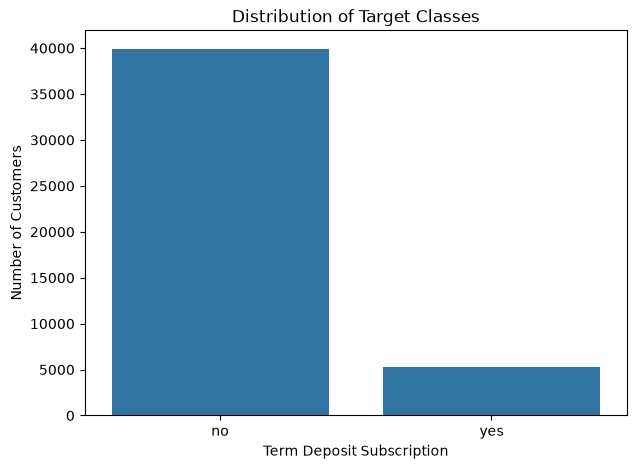

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="y")

plt.title("Distribution of Target Classes")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

plt.savefig("../Outputs/graph1_class_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()

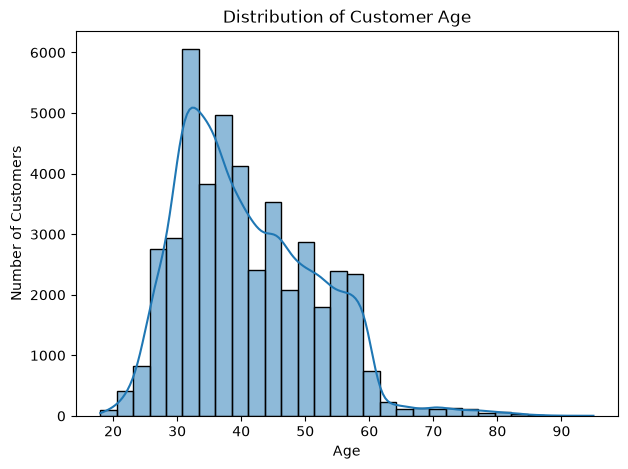

In [17]:
plt.figure(figsize=(7, 5))

sns.histplot(data=df, x="age", bins=30, kde=True)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.savefig("../Outputs/graph2_age_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()

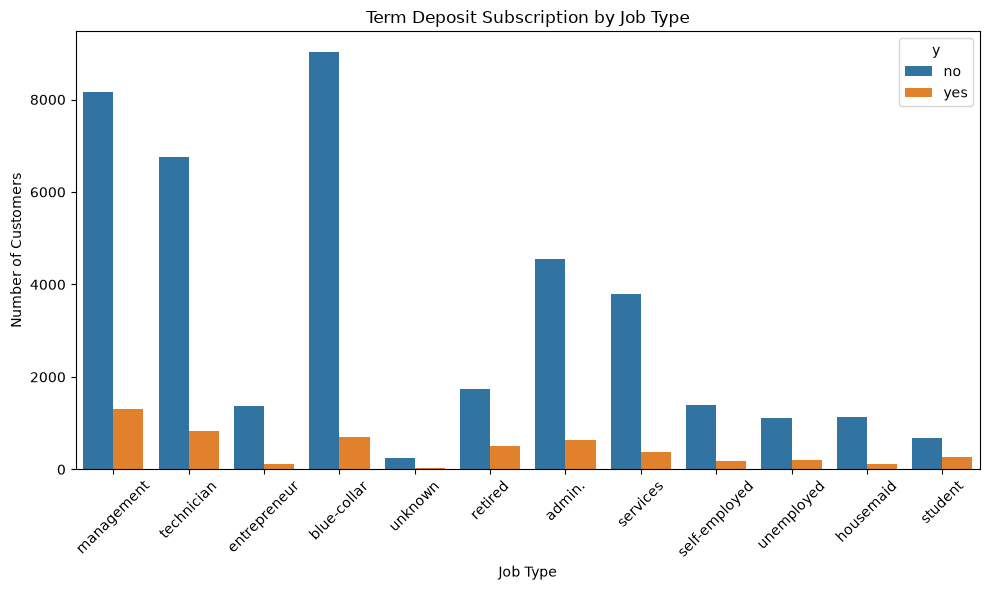

In [19]:
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x="job", hue="y")

plt.title("Term Deposit Subscription by Job Type")
plt.xlabel("Job Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig("../Outputs/graph3_job_subscription.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [20]:
df = df.drop(columns=["duration"])

print("Dataset shape after removing duration:", df.shape)

Dataset shape after removing duration: (45211, 16)


In [21]:
X = df.drop(columns=["y"])
y = df["y"].map({"no": 0, "yes": 1})

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Input features shape: (45211, 15)
Target shape: (45211,)

Target classes:
y
0    39922
1     5289
Name: count, dtype: int64


In [22]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 31647
Validation samples: 6782
Testing samples: 6782


In [23]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:", categorical_columns)
print("Numerical features:", numerical_columns)

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_40040\556407945.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(


In [24]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

In [25]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Validation data shape:", X_val_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (31647, 50)
Validation data shape: (6782, 50)
Testing data shape: (6782, 50)


In [28]:
import os
import joblib
import numpy as np

# Create Outputs folder if it does not exist
os.makedirs("../Outputs", exist_ok=True)

# Save preprocessor
joblib.dump(preprocessor, "../Outputs/preprocessor.pkl")

# Save processed input features
np.save("../Outputs/X_train.npy", X_train_processed)
np.save("../Outputs/X_val.npy", X_val_processed)
np.save("../Outputs/X_test.npy", X_test_processed)

# Save target labels
np.save("../Outputs/y_train.npy", y_train.to_numpy())
np.save("../Outputs/y_val.npy", y_val.to_numpy())
np.save("../Outputs/y_test.npy", y_test.to_numpy())

print("Processed data and preprocessor saved successfully!")

Processed data and preprocessor saved successfully!


In [38]:
import torch

print("PyTorch version:", torch.__version__)
print("PyTorch available:", True)

PyTorch version: 2.14.0+cpu
PyTorch available: True
